# Training Notebook
- This notebook was initially used to set up the training process
- The actual training was performed with the `train_script.py` (on the hpc branch) and ran on the HPC server
- This notebook is a good reference for the general training workflow and can be executed cell by cell to understand the training process

In [1]:
import torch
import torch.optim as optim
import numpy as np
from torch.optim.lr_scheduler import LinearLR, CosineAnnealingLR, SequentialLR

# Add project directories so local modules import correctly
import sys
from pathlib import Path

cwd = Path.cwd().resolve()
repo_root = None
for cand in [cwd, *cwd.parents]:
    if (cand / "04_modeling").exists() and (cand / "03_datapreparation").exists():
        repo_root = cand
        break

if repo_root is None:
    repo_root = cwd

for p in (repo_root / "04_modeling", repo_root / "03_datapreparation", repo_root / "03_datapreparation" / "augmentation"):
    p_str = str(p)
    if p_str not in sys.path:
        sys.path.append(p_str)


# Models
from models.deeplab import DeepLabV3Plus
from models.segformer import SegFormer
from models.unet import UNet
# Utils
from utils.focal_loss import FocalLoss
# Dataset, DataLoader and Transforms
from cityscapes_dataset import CityscapesDataset
from torch.utils.data import DataLoader
import torchvision.transforms.functional as F
from PIL import Image
# For visualization, logging
from tqdm import tqdm
import matplotlib.pyplot as plt
from torch.utils.tensorboard import SummaryWriter

from augmentations import (
    JointCompose, JointToTensor, JointResize, JointRandomHorizontalFlip,
    JointRandomAffine, JointColorJitter, RandomBlur, RandomNoise,
    RandomCoarseDropout, OneOf, JointRandomScale, JointRandomCrop
)

## Evaluation Criteria Functions

In [2]:
def compute_miou(pred, truth, num_classes, ignore_index=255): 
    ious = []
    pred = pred.flatten()
    truth = truth.flatten()

    # Remove label values of ignore_index
    mask = truth != ignore_index
    pred = pred[mask]
    truth = truth[mask]

    for clas in range(num_classes):
        pred_clas = pred == clas
        truth_clas = truth == clas
        intersection = (pred_clas & truth_clas).sum().item()
        union = (pred_clas | truth_clas).sum().item()
        if union == 0:
            ious.append(float("nan"))
        else:
            ious.append(intersection/union)
    return np.nanmean(ious), ious

def compute_accuracy(pred, truth, ignore_index=255):
    # Remove label values of ignore_index
    mask = truth != ignore_index
    pred = pred[mask]
    truth = truth[mask]

    return (pred == truth).float().mean()

## Training Loop
In each step:
- Load input images and labels to `device`
- Forward pass
- Compute `loss`
- Backpropagate gradients with `loss.backward()`
- Update parameters with `optimizer.step()`
- Compute metrics `loss`, `accuracy`, `mIoU`

In [3]:
def train(dataloader, model, loss_function, optimizer, device, num_classes, scheduler):
    # Switch to train mode
    model.train()

    # For storing running metrics
    epoch_loss, epoch_acc, epoch_miou = 0, 0, 0

    # Create a progress bar
    pbar = tqdm(dataloader, desc="Training loop", leave=False)
    for images, labels in pbar:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        ### Forward pass
        # Get output/prediction
        output = model(images)
        # Calculate loss
        loss = loss_function(output, labels)

        ### Backpropagation
        # Gradients have to be zeroed for each batch
        optimizer.zero_grad()
        # Calculate the gradients
        loss.backward()
        # Update the parameters
        optimizer.step()
        # Scheduler step
        scheduler.step()  

        ### Calculate metrics per batch
        prediction = output.argmax(dim=1)

        acc = compute_accuracy(prediction, labels)
        miou, _ = compute_miou(prediction, labels, num_classes)
        epoch_loss += loss.item()
        epoch_acc += acc.item()
        epoch_miou += miou

    # Return metrics averaged across all batches
    num_batches = len(dataloader)
    return epoch_loss/num_batches, epoch_acc/num_batches, epoch_miou/num_batches

## Validationloop
In each step:
- Load input images and labels to `device`
- Forward pass
- Compute `loss`
- Compute metrics `loss`, `accuracy`, `mIoU`

In [4]:
def valid(dataloader, model, loss_function, device, num_classes):
    # Switch to eval mode
    model.eval()

    # For storing running metrics
    epoch_loss, epoch_acc, epoch_miou = 0, 0, 0

    # Create a progress bar
    pbar = tqdm(dataloader, desc="Validation loop", leave=False)
    # Disable gradient calculation
    with torch.no_grad():
        for images, labels in pbar:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            ### Forward pass
            # Get output/prediction
            output = model(images)
            # Calculate loss
            loss = loss_function(output, labels)

            ### Calculate metrics per batch
            prediction = output.argmax(dim=1)

            acc = compute_accuracy(prediction, labels)
            miou, _ = compute_miou(prediction, labels, num_classes)
            epoch_loss += loss.item()
            epoch_acc += acc.item()
            epoch_miou += miou
    
    # Return metrics averaged across all batches
    num_batches = len(dataloader)
    return epoch_loss/num_batches, epoch_acc/num_batches, epoch_miou/num_batches
            
            

## Create the DataLoaders
- Define transforms
- Set paths for images and annotations
- Initialize datasets for `train` and `val` splits
- Initialize dataloaders with `batch_size`

In [5]:
# Crop size for training
crop_height, crop_width = 512, 1024
# Resize size for validation
height, width = 512, 1024

# Joint transforms for training with augmentation
joint_train_transforms = JointCompose([
    JointRandomScale(scale_range=(0.5, 1.0)),
    JointRandomCrop(size=(crop_height, crop_width)),
    JointRandomHorizontalFlip(p=0.5),
    JointColorJitter(brightness=0.4, contrast=0.4, saturation=0.4, hue=0.1),
    JointToTensor(),
])

# Joint transforms for validation (resize only)
joint_valid_transforms = JointCompose([
    JointResize(size=(height, width)),
    JointToTensor()
])

def joint_train_transform(image, label):
    image, label = Image.fromarray(image), Image.fromarray(label)
    image, label = joint_train_transforms(image, label)
    return image, label

def joint_valid_transform(image, label):
    image, label = Image.fromarray(image), Image.fromarray(label)
    image, label = joint_valid_transforms(image, label)
    return image, label

### Transforms to resize images, labels

def image_transform(image):
    image = Image.fromarray(image)  # numpy -> PIL
    image = F.resize(image, (height, width), interpolation=F.InterpolationMode.BILINEAR) # Bilinear for RGB-Images
    image = F.pil_to_tensor(image).float() / 255.0  # Scaling
    return image


def label_transform(label):
    label = Image.fromarray(label)  # numpy -> PIL
    label = F.resize(label, (height, width), interpolation=F.InterpolationMode.NEAREST) # Nearest Neighbor for Labels
    label = F.pil_to_tensor(label).long().squeeze()  # PIL -> LongTensor no Scaling, squeeze() to remove channel dimension
    return label


# Define data paths
data_dir = Path("../data/cityscapes_intersections_heading/fine_intersections_4")
image_dir = data_dir / "leftImg8bit_trainvaltest/leftImg8bit"
label_dir = data_dir / "gtFine_trainvaltest/gtFine"

# Initialize datasets
train_dataset = CityscapesDataset(image_dir, label_dir, split="train", joint_transform=joint_train_transform)
valid_dataset = CityscapesDataset(image_dir, label_dir, split="val", joint_transform=joint_valid_transform)

# Create the dataloaders
train_dataloader = DataLoader(train_dataset, batch_size=2, shuffle=True)
valid_dataloader = DataLoader(valid_dataset, batch_size=2, shuffle=False)

for images, labels in train_dataloader:
    print(f"Images of first batch: {images.shape}")
    print(f"Labels of first batch: {labels.shape}")
    break

for images, labels in valid_dataloader:
    print(f"Images of first batch: {images.shape}")
    print(f"Labels of first batch: {labels.shape}")
    break

Images of first batch: torch.Size([2, 3, 512, 1024])
Labels of first batch: torch.Size([2, 512, 1024])
Images of first batch: torch.Size([2, 3, 512, 1024])
Labels of first batch: torch.Size([2, 512, 1024])


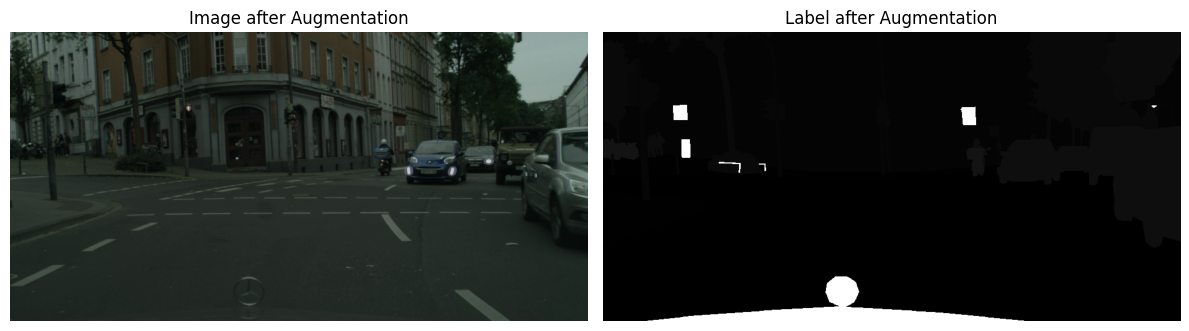

In [7]:
# Get first image and label from train_dataset
image, label = train_dataset[0]

# Create figure with two subplots
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Plot image (convert from tensor to numpy)
axes[0].imshow(image.permute(1, 2, 0))  # CHW -> HWC
axes[0].set_title("Image after Augmentation")
axes[0].axis("off")

# Plot label (convert from tensor to numpy)
axes[1].imshow(label.numpy(), cmap="gray")
axes[1].set_title("Label after Augmentation")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [8]:
def build_warmup_cosine_scheduler(optimizer, base_lr, min_lr, total_iters, warmup_iters):
    warmup_scheduler = LinearLR(
        optimizer,
        start_factor=0.01,      # start at 1%
        total_iters=warmup_iters
    )

    cosine_scheduler = CosineAnnealingLR(
        optimizer,
        T_max=total_iters - warmup_iters,
        eta_min=min_lr
    )

    scheduler = SequentialLR(
        optimizer,
        schedulers=[warmup_scheduler, cosine_scheduler],
        milestones=[warmup_iters]
    )
    return scheduler

In [ ]:
### Hyperparameters
num_epochs = 150
warmup_epochs = 10
save_at_epochs = 150

lr = 1e-3
min_lr = 1e-6
weight_decay = 1e-4

# Path to save checkpoints
run = "run99"
directory = Path("../checkpoints") / run
directory.mkdir(parents=True, exist_ok=True)

# For logging to tensorboard
writer = SummaryWriter(log_dir=f"../logs/{run}")

# Define the device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

# Initialize model and move to device
num_classes = 20    # current trainIds
model = UNet(num_classes).to(device)
model_name = model.name

# Load checkpoint with torch.load (optionally)
loaded_checkpoint = None
loaded_epochs = 0

# Define optimizer and loss function   
loss_function = FocalLoss(gamma=2, ignore_index=255)
optimizer = optim.AdamW(params=model.parameters(), lr=lr, weight_decay=weight_decay)


# Initialize scheduler
iters_per_epoch = len(train_dataloader)
warmup_iters = warmup_epochs * iters_per_epoch
total_iters = num_epochs * iters_per_epoch
scheduler = build_warmup_cosine_scheduler(optimizer=optimizer, base_lr=lr, min_lr=min_lr, total_iters=total_iters, warmup_iters=warmup_iters)

best_val_miou = 0.0

if loaded_checkpoint:
    model.load_state_dict(loaded_checkpoint["model_state_dict"])
    loaded_epochs = loaded_checkpoint["epoch"]
    optimizer.load_state_dict(loaded_checkpoint["optimizer_state_dict"])
    best_val_miou = loaded_checkpoint["val_miou"]
    
pbar = tqdm(range(num_epochs))
for epoch in pbar:
    pbar.set_description(f"Epoch {epoch+1}/{num_epochs}")

    # Call train and validation loops
    train_loss, train_acc, train_miou = train(
        train_dataloader, model, loss_function, optimizer, device, num_classes, scheduler
        )
    val_loss, val_acc, val_miou = valid(
        valid_dataloader, model, loss_function, device, num_classes
        )
    
    checkpoint = {
        "epoch": loaded_epochs + epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "train_loss": train_loss,
        "val_loss": val_loss,
        "train_acc": train_acc,
        "val_acc": val_acc,
        "train_miou": train_miou,
        "val_miou": val_miou
    }

    # Save the model every {save_at_epochs} epochs
    if (epoch + 1) % save_at_epochs == 0:
        torch.save(checkpoint, f"../checkpoints/{run}/{model_name}_epoch_{loaded_epochs + epoch}")

    # Save the best model
    if val_miou > best_val_miou:
        best_val_miou = val_miou
        torch.save(checkpoint, f"../checkpoints/{run}/best_{model_name}")

    
    # Update the progress bar with metrics from current epoch
    pbar.set_postfix({
                "Train Loss": f"{train_loss:.3f}",
                "Val Loss": f"{val_loss:.3f}",
                "Train Acc": f"{train_acc:.3f}",
                "Val Acc": f"{val_acc:.3f}",
                "Train MIoU": f"{train_miou:.3f}",
                "Val MIoU": f"{val_miou:.3f}",
            })

    current_lr = optimizer.param_groups[0]["lr"]
    writer.add_scalar("TRAINING/lr", current_lr, global_step=epoch)
    writer.add_scalars("TRAINING/loss", {"train loss": train_loss, "val loss": val_loss}, global_step=epoch)
    writer.add_scalars("TRAINING/acc", {"train acc": train_acc, "val acc": val_acc}, global_step=epoch)
    writer.add_scalars("TRAINING/MIoU", {"train MIoU": train_miou, "val MIoU": val_miou}, global_step=epoch)
    writer.flush()

writer.close()